# 04 · Business back-test

Notebook 03 measures accuracy (RMSLE). Here we ask the question a studio, financier or distributor would ask: **if we had used the model's forecasts to make decisions, would we have picked better bets?**

We turn each test film's revenue forecast into a business call using the industry rule of thumb that a film needs about **2.5× its budget** in worldwide gross to break even, then compare the calls with what actually happened.

| Model's call | Forecast gross ÷ budget |
|---|---|
| Likely smash | ≥ 2.5× |
| Uncertain | 1× to 2.5× |
| Likely bomb | < 1× |

Only test films with a known budget can be judged this way. The test films are used exactly as in notebook 03: the model is fitted on the train and validation films and never sees them.

1. Imports
2. Load
3. Refit the full model
4. From forecast to business call
5. Did the calls work?
6. Smashes caught and bombs avoided
7. Portfolio view
8. Ranking
9. By budget size
10. Choosing the threshold
11. Key numbers

## 1. Imports

In [7]:
#pip install pyarrow xgboost scipy

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import pyarrow 
from scipy.stats import spearmanr
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", context="notebook")

BREAK_EVEN = 2.5          # worldwide gross / budget needed to break even (rule of thumb)
CALLS = ["Likely smash", "Uncertain", "Likely bomb"]
COLORS = {"Likely smash": "#1E7B4F", "Uncertain": "#C98A00", "Likely bomb": "#B3261E"}

## 2. Load

`features.parquet` from notebook 02, plus the budget in 2025 dollars from notebook 01 (the features only hold its log).

In [ ]:
feat = pd.read_parquet("C:\...\features.parquet")
budget = pd.read_parquet("C:...\\movies_clean.parquet")[["imdb_id", "budget_cpi"]]
print(feat.shape)
feat["split"].value_counts()

(6090, 130)


split
train    4263
test      914
val       913
Name: count, dtype: int64

## 3. Refit the full model

Same feature set and hyperparameters as notebook 03 ("XGBoost: full"), fitted on all train and validation films and scored once on the test films. XGBoost results can differ in the third decimal between library versions and machines.

In [10]:
id_cols = ["imdb_id", "title", "split", "log_revenue_cpi", "revenue_cpi"]
track = [c for c in feat if c.startswith(("exp_", "prev_rev_"))]
plot = [c for c in feat if c.startswith("plot_emb_")]
keyword = [c for c in feat if c.startswith("kw_emb_")]
structured = [c for c in feat if c not in id_cols + track + plot + keyword]
full = structured + track + plot + keyword

XGB_PARAMS = dict(n_estimators=3000, learning_rate=0.03, max_depth=5, min_child_weight=3, subsample=0.8,
                  colsample_bytree=0.8, reg_lambda=1.0, early_stopping_rounds=100, eval_metric="rmse",
                  random_state=42)

y = feat["log_revenue_cpi"]
dev = feat["split"].isin(["train", "val"])
te = feat["split"] == "test"

X_fit, X_stop, y_fit, y_stop = train_test_split(feat.loc[dev, full], y[dev], test_size=0.15, random_state=42)
model = xgb.XGBRegressor(**XGB_PARAMS).fit(X_fit, y_fit, eval_set=[(X_stop, y_stop)], verbose=False)
pred = model.predict(feat.loc[te, full])

print(f"test RMSLE {np.sqrt(mean_squared_error(y[te], pred)):.3f}   "
      f"typical miss x{np.exp(mean_absolute_error(y[te], pred)):.1f}   (notebook 03: 1.350, x2.8)")

test RMSLE 1.350   typical miss x2.8   (notebook 03: 1.350, x2.8)


## 4. From forecast to business call

For each test film: forecast gross ÷ budget gives the model's call, and actual gross ÷ budget tells us what happened. A film **broke even** if it earned at least 2.5× its budget, and **lost money** if it earned less than its budget.

In [11]:
bt = (feat.loc[te, ["imdb_id", "title", "revenue_cpi", "log_revenue_cpi"]]
          .assign(pred_log=pred, pred_rev=np.expm1(pred))
          .merge(budget, on="imdb_id"))
print(f"test films: {len(bt):,}   with a known budget: {bt['budget_cpi'].notna().sum():,}")
bt = bt.dropna(subset=["budget_cpi"]).reset_index(drop=True)

bt["actual_x"] = bt["revenue_cpi"] / bt["budget_cpi"]
bt["pred_x"] = bt["pred_rev"] / bt["budget_cpi"]
bt["broke_even"] = bt["actual_x"] >= BREAK_EVEN
bt["lost_money"] = bt["actual_x"] < 1
bt["call"] = pd.Categorical(np.select([bt["pred_x"] >= BREAK_EVEN, bt["pred_x"] >= 1], CALLS[:2], CALLS[2]),
                            categories=CALLS, ordered=True)
bt[["title", "budget_cpi", "pred_rev", "revenue_cpi", "pred_x", "actual_x", "call"]].head()

test films: 914   with a known budget: 674


,title,budget_cpi,pred_rev,revenue_cpi,pred_x,actual_x,call
0,The Spanish Prisoner,2.005875e+07,13363059.0,1.924417e+07,0.666196,0.959390,Likely bomb
1,The Last Witch Hunter,1.222481e+08,198851040.0,1.995861e+08,1.626619,1.632632,Uncertain
2,Outbreak,1.056243e+08,201025872.0,4.010758e+08,1.903215,3.797191,Uncertain
3,The Jacket,4.780516e+07,48512792.0,3.582622e+07,1.014803,0.749422,Uncertain
4,Cry-Baby,2.709543e+07,52331220.0,2.036260e+07,1.931367,0.751514,Uncertain


## 5. Did the calls work?

If the model's calls carry information, films it called smashes should break even far more often than average, and films it called bombs should lose money far more often.

In [12]:
def summarise(d):
    return pd.Series({
        "films": len(d),
        "share of films": len(d) / len(bt),
        "broke even (>=2.5x)": d["broke_even"].mean(),
        "lost money (<1x)": d["lost_money"].mean(),
        "median gross / budget": d["actual_x"].median(),
        "total gross / total budget": d["revenue_cpi"].sum() / d["budget_cpi"].sum(),
    })

calls = pd.concat([bt.groupby("call", observed=True).apply(summarise),
                   summarise(bt).rename("All test films").to_frame().T])
calls.style.format({"films": "{:.0f}", "share of films": "{:.0%}", "broke even (>=2.5x)": "{:.0%}",
                    "lost money (<1x)": "{:.0%}", "median gross / budget": "{:.2f}x",
                    "total gross / total budget": "{:.2f}x"})

,films,share of films,broke even (>=2.5x),lost money (<1x),median gross / budget,total gross / total budget
Likely smash,168,25%,64%,12%,4.05x,4.53x
Uncertain,385,57%,41%,25%,2.02x,2.65x
Likely bomb,121,18%,18%,59%,0.82x,1.71x
All test films,674,100%,42%,28%,2.04x,3.04x


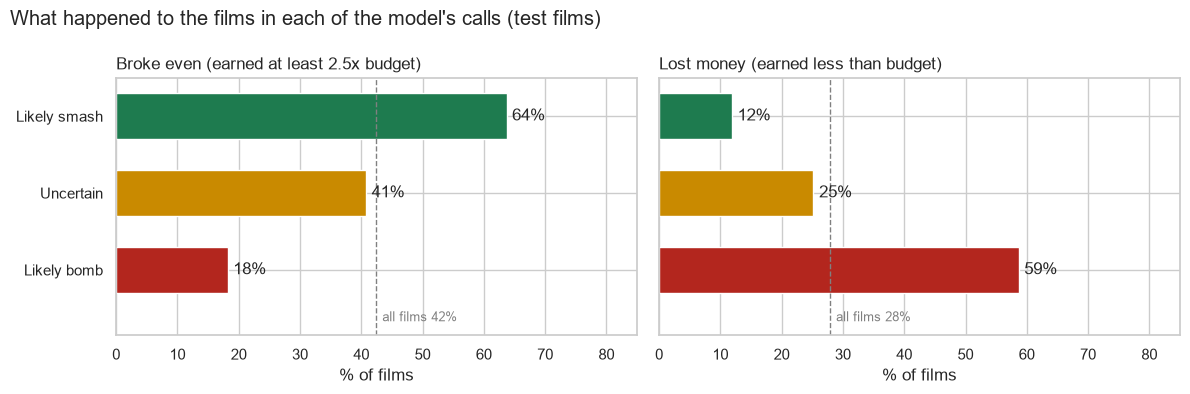

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, col, title in [(axes[0], "broke even (>=2.5x)", "Broke even (earned at least 2.5x budget)"),
                       (axes[1], "lost money (<1x)", "Lost money (earned less than budget)")]:
    vals = calls.loc[CALLS, col]
    bars = ax.barh(CALLS[::-1], vals[::-1] * 100, color=[COLORS[c] for c in CALLS[::-1]], height=0.6)
    ax.axvline(calls.loc["All test films", col] * 100, color="gray", ls="--", lw=1)
    ax.text(calls.loc["All test films", col] * 100 + 1, -0.62, f"all films {calls.loc['All test films', col]:.0%}",
            color="gray", fontsize=9, va="center")
    ax.set_ylim(-0.85, 2.5)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in vals[::-1]], padding=4)
    ax.set_xlim(0, 85); ax.set_xlabel("% of films"); ax.set_title(title, loc="left")
plt.suptitle("What happened to the films in each of the model's calls (test films)", x=0.01, ha="left")
plt.tight_layout()

## 6. Smashes caught and bombs avoided

Section 5 shows the calls are reliable when the model makes them. The other side is coverage: how many of the films that *actually* broke even, or *actually* lost money, did the model call correctly in advance?

In [14]:
outcome = pd.Series(np.select([bt["broke_even"], bt["lost_money"]], ["broke even", "lost money"], "in between"),
                    index=bt.index, name="what actually happened")
pd.crosstab(bt["call"].rename("model's call"), outcome,
            margins=True, margins_name="total").reindex(columns=["broke even", "in between", "lost money", "total"])

what actually happened,broke even,in between,lost money,total
model's call,,,,
Likely smash,107,41,20,168
Uncertain,157,131,97,385
Likely bomb,22,28,71,121
total,286,200,188,674


In [15]:
caught_smash = (bt["call"].eq("Likely smash") & bt["broke_even"]).sum() / bt["broke_even"].sum()
caught_bomb = (bt["call"].eq("Likely bomb") & bt["lost_money"]).sum() / bt["lost_money"].sum()
missed_smash = (bt["call"].eq("Likely bomb") & bt["broke_even"]).sum()
print(f"Films that broke even, called 'likely smash' in advance: {caught_smash:.0%}")
print(f"Films that lost money, called 'likely bomb' in advance:  {caught_bomb:.0%}")
print(f"Films called 'likely bomb' that actually broke even:     {missed_smash}")

Films that broke even, called 'likely smash' in advance: 37%
Films that lost money, called 'likely bomb' in advance:  38%
Films called 'likely bomb' that actually broke even:     22


The model is **cautious**: when it calls a smash or a bomb it is usually right, but most films land in the uncertain middle, so it catches only part of the eventual hits and flops. Used as a hard filter, it would reject some future hits.

## 7. Portfolio view

Treat the test films as a studio's slate. How does the slate perform if we fund every film, every film except the likely bombs, or only the likely smashes? We use total worldwide gross ÷ total budget (2025 dollars) for each strategy.

In [16]:
strategies = {
    "Fund every film": bt,
    "Skip the likely bombs": bt[bt["call"] != "Likely bomb"],
    "Fund only likely smashes": bt[bt["call"] == "Likely smash"],
    "(for reference) the likely bombs": bt[bt["call"] == "Likely bomb"],
}
portfolio = pd.DataFrame({k: {"films": len(d),
                              "budget, $bn": d["budget_cpi"].sum() / 1e9,
                              "gross, $bn": d["revenue_cpi"].sum() / 1e9,
                              "gross / budget": d["revenue_cpi"].sum() / d["budget_cpi"].sum(),
                              "share that lost money": d["lost_money"].mean()}
                          for k, d in strategies.items()}).T
portfolio.style.format({"films": "{:.0f}", "budget, $bn": "{:.1f}", "gross, $bn": "{:.1f}",
                        "gross / budget": "{:.2f}x", "share that lost money": "{:.0%}"})

,films,"budget, $bn","gross, $bn",gross / budget,share that lost money
Fund every film,674,41.2,125.6,3.04x,28%
Skip the likely bombs,553,36.4,117.3,3.22x,21%
Fund only likely smashes,168,11.0,50.0,4.53x,12%
(for reference) the likely bombs,121,4.9,8.3,1.71x,59%


Gross ÷ budget is not profit: theaters keep roughly half of ticket sales and marketing is not counted. It is still a fair way to compare strategies on the same slate.

## 8. Ranking

Distributors and exhibitors mostly need the right *order*: which upcoming films will earn the most.

In [17]:
all_te = feat.loc[te, ["revenue_cpi", "log_revenue_cpi"]].assign(pred_log=pred)
top_actual = all_te["revenue_cpi"] >= all_te["revenue_cpi"].quantile(0.9)
top_pred = all_te["pred_log"] >= all_te["pred_log"].quantile(0.9)
print(f"Rank correlation (Spearman), forecast vs actual: {spearmanr(all_te['pred_log'], all_te['log_revenue_cpi'])[0]:.2f}")
print(f"True top-10% earners that are also in the model's top 10%: {(top_actual & top_pred).sum() / top_actual.sum():.0%} "
      f"(random: 10%)")

Rank correlation (Spearman), forecast vs actual: 0.80
True top-10% earners that are also in the model's top 10%: 61% (random: 10%)


## 9. By budget size

Is the model more useful for some kinds of film than others?

In [18]:
bt["budget band"] = pd.cut(bt["budget_cpi"], [0, 20e6, 66e6, np.inf], labels=["under $20M", "$20M-66M", "over $66M"])
abs_err = (bt["pred_log"] - bt["log_revenue_cpi"]).abs()

def band_summary(d):
    e = abs_err[d.index]
    smash = d["call"] == "Likely smash"
    bomb = d["call"] == "Likely bomb"
    return pd.Series({"films": len(d),
                      "broke even, all": d["broke_even"].mean(),
                      "broke even, called smash": d.loc[smash, "broke_even"].mean(),
                      "lost money, called bomb": d.loc[bomb, "lost_money"].mean(),
                      "typical miss": np.exp(e.mean()),
                      "forecast within 2x": (e < np.log(2)).mean()})

bands = bt.groupby("budget band", observed=True).apply(band_summary)
bands.style.format({"films": "{:.0f}", "broke even, all": "{:.0%}", "broke even, called smash": "{:.0%}",
                    "lost money, called bomb": "{:.0%}", "typical miss": "x{:.1f}", "forecast within 2x": "{:.0%}"})

,films,"broke even, all","broke even, called smash","lost money, called bomb",typical miss,forecast within 2x
budget band,,,,,,
under $20M,202,44%,70%,59%,x3.3,40%
$20M-66M,269,42%,59%,57%,x2.5,49%
over $66M,203,41%,62%,61%,x1.9,64%


The dollar forecast is much tighter for large films, but the smash and bomb calls are informative at every budget size.

## 10. Choosing the threshold

The 2.5× cut-off is a rule of thumb. Raising the bar for a "likely smash" call makes the call more reliable but flags fewer films. A decision-maker can pick the trade-off that suits their risk appetite.

,threshold,share of films flagged,flagged that broke even,break-even films caught
0,1.0,0.82,0.48,0.92
2,1.5,0.62,0.52,0.77
4,2.0,0.41,0.59,0.57
6,2.5,0.25,0.64,0.37
8,3.0,0.14,0.68,0.22
10,3.5,0.09,0.76,0.16
12,4.0,0.07,0.82,0.13
14,4.5,0.05,0.85,0.10
16,5.0,0.04,0.88,0.08


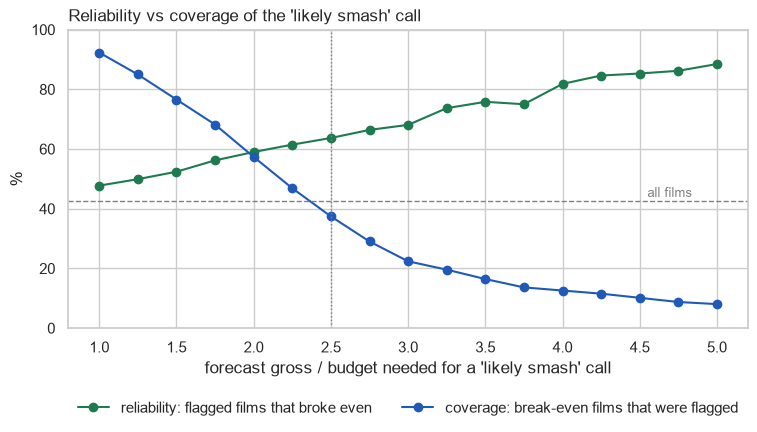

In [19]:
rows = []
for t in np.arange(1.0, 5.01, 0.25):
    flagged = bt["pred_x"] >= t
    rows.append({"threshold": t, "share of films flagged": flagged.mean(),
                 "flagged that broke even": bt.loc[flagged, "broke_even"].mean(),
                 "break-even films caught": (flagged & bt["broke_even"]).sum() / bt["broke_even"].sum()})
thr = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(thr["threshold"], thr["flagged that broke even"] * 100, marker="o", color="#1E7B4F",
        label="reliability: flagged films that broke even")
ax.plot(thr["threshold"], thr["break-even films caught"] * 100, marker="o", color="#205AB9",
        label="coverage: break-even films that were flagged")
ax.axhline(bt["broke_even"].mean() * 100, color="gray", ls="--", lw=1)
ax.text(4.55, bt["broke_even"].mean() * 100 + 1.5, "all films", color="gray", fontsize=9)
ax.axvline(BREAK_EVEN, color="gray", ls=":", lw=1)
ax.set_xlabel("forecast gross / budget needed for a 'likely smash' call")
ax.set_ylabel("%"); ax.set_ylim(0, 100)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
ax.set_title("Reliability vs coverage of the 'likely smash' call", loc="left")
plt.tight_layout()
thr.iloc[::2].round(2)

## 11. Key numbers

The figures used in the executive summary.

In [20]:
cs = calls.loc["Likely smash"]; cb = calls.loc["Likely bomb"]; ca = calls.loc["All test films"]
print(f"Test films with a known budget:                 {len(bt)}")
print(f"'Likely smash' films that broke even:           {cs['broke even (>=2.5x)']:.0%}  (all films {ca['broke even (>=2.5x)']:.0%})")
print(f"'Likely bomb' films that lost money:            {cb['lost money (<1x)']:.0%}  (all films {ca['lost money (<1x)']:.0%})")
print(f"Gross / budget, 'likely smash' films:           {cs['total gross / total budget']:.1f}x  (all films {ca['total gross / total budget']:.1f}x)")
print(f"Share of films in the uncertain middle:         {calls.loc['Uncertain', 'share of films']:.0%}")
print(f"Break-even films caught as 'likely smash':      {caught_smash:.0%}")
print(f"True top-10% earners in the model's top 10%:    {(top_actual & top_pred).sum() / top_actual.sum():.0%}")

Test films with a known budget:                 674
'Likely smash' films that broke even:           64%  (all films 42%)
'Likely bomb' films that lost money:            59%  (all films 28%)
Gross / budget, 'likely smash' films:           4.5x  (all films 3.0x)
Share of films in the uncertain middle:         57%
Break-even films caught as 'likely smash':      37%
True top-10% earners in the model's top 10%:    61%
